In [ ]:
import pandas as pd
import json
import numpy as np
import ast
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import re

# Load the data
df = pd.read_csv('train_classifier.csv')
df.shape

(4357, 2)

In [13]:
df

,question,label,query_length
0,Dưới bao nhiêu tuổi thì được coi là trẻ nhỏ?,Trẻ em,10
1,Trẻ con được xác định theo độ tuổi nào?,Trẻ em,9
2,Người 15 tuổi có được coi là trẻ em không?,Trẻ em,10
3,Luật trẻ em quy định những gì về quyền và bổn ...,Trẻ em,15
4,Ai có trách nhiệm đảm bảo quyền của con nít th...,Trẻ em,14
...,...,...,...
4352,Trường đại học cần điều kiện gì để mở ngành đà...,Khác,13
4353,Ai có quyền bổ nhiệm hiệu trưởng trường đại học?,Khác,10
4354,Luật Giáo dục đại học có quy định gì về học phí?,Khác,12
4355,Sinh viên có quyền lợi gì theo Luật Giáo dục đ...,Khác,12


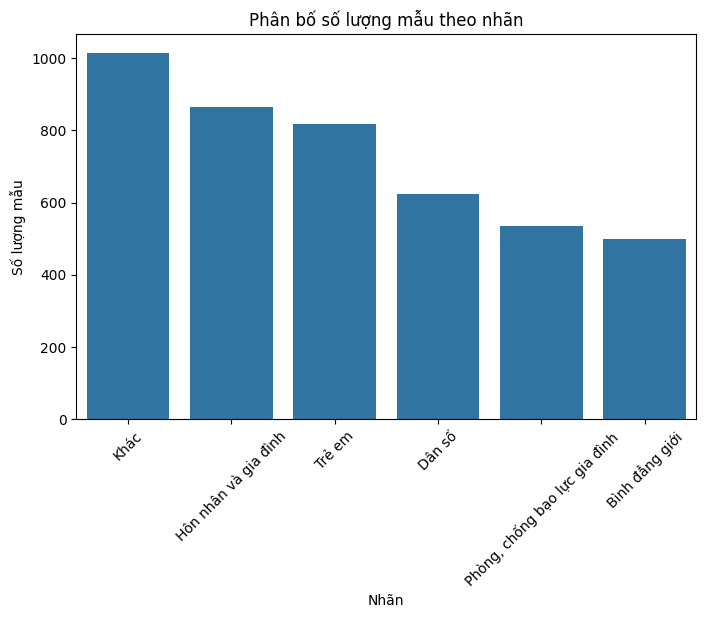

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='label', order=df['label'].value_counts().index)
plt.title("Phân bố số lượng mẫu theo nhãn")
plt.xlabel("Nhãn")
plt.ylabel("Số lượng mẫu")
plt.xticks(rotation=45)
plt.show()


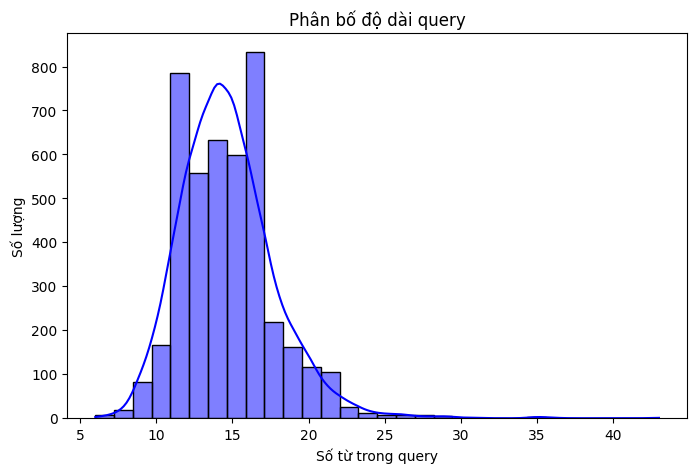

In [9]:
df['query_length'] = df['question'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(8, 5))
sns.histplot(df['query_length'], bins=30, kde=True, color='blue')
plt.title("Phân bố độ dài query")
plt.xlabel("Số từ trong query")
plt.ylabel("Số lượng")
plt.show()


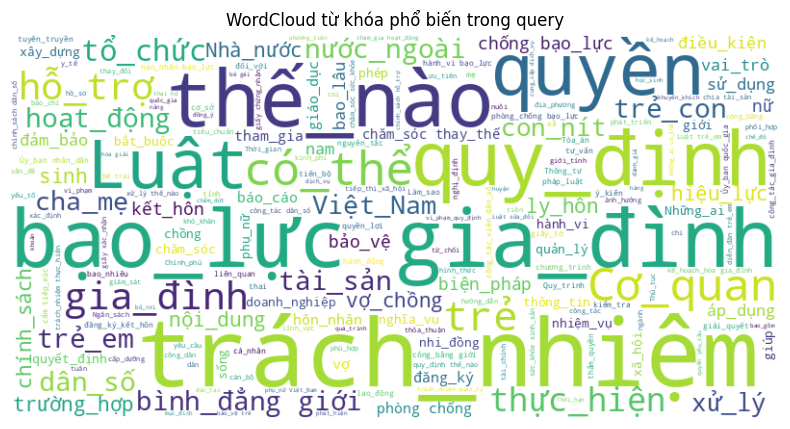

In [10]:
from wordcloud import WordCloud
import pyvi.ViTokenizer

with open("vietnamese-stopwords.txt", "r", encoding="utf-8") as f:
    vietnamese_stopwords = set(f.read().splitlines())

# Tiền xử lý văn bản (tách từ tiếng Việt)
text = " ".join(df['question'].astype(str).tolist())
text = pyvi.ViTokenizer.tokenize(text)  

# Tạo WordCloud
wordcloud = WordCloud(width=800, height=400, background_color="white", stopwords=vietnamese_stopwords).generate(text)

# Hiển thị WordCloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud từ khóa phổ biến trong query")
plt.show()


In [12]:
# Thống kê mô tả cơ bản cho các biến số số học
print("Thống kê mô tả:")
print(df.describe())

# Nếu cần, in ra các giá trị đặc trưng theo nhãn
print("\nThống kê độ dài query theo nhãn:")
print(df.groupby("label")["query_length"].describe())


Thống kê mô tả:
       query_length
count   4357.000000
mean      14.667202
std        3.142303
min        6.000000
25%       13.000000
50%       14.000000
75%       16.000000
max       43.000000

Thống kê độ dài query theo nhãn:
                                count       mean       std  min   25%   50%  \
label                                                                         
Bình đẳng giới                  500.0  16.616000  3.475154  8.0  14.0  16.0   
Dân số                          624.0  14.576923  2.765387  8.0  13.0  14.0   
Hôn nhân và gia đình            864.0  14.935185  3.043213  6.0  13.0  15.0   
Khác                           1015.0  12.783251  2.263752  6.0  11.0  13.0   
Phòng, chống bạo lực gia đình   536.0  15.645522  2.684204  9.0  14.0  15.0   
Trẻ em                          818.0  14.958435  3.323921  8.0  13.0  15.0   

                                75%   max  
label                                      
Bình đẳng giới                 19.0  29.0  
Dân s